# Modelo 3 corregido — HistGradientBoostingClassifier | Grupo 19

**Protocolo comparable con regresión logística v2 y árbol de decisión corregido.** Se utiliza el mismo CSV, variables A/B, partición por hogar con semillas 42/43, PR-AUC de validación para elegir hiperparámetros, umbral que maximiza F1 en validación, y métricas de **prueba** para la comparación final. Incluye priorización top 10/20/30 %, tablas y MLflow compartido.

## 0. Librerias / configuración




In [7]:
from pathlib import Path
import os, json, hashlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, ParameterSampler, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from IPython.display import display
try:
    import mlflow
except ImportError:
    mlflow = None
    print('MLflow no instalado: se guardarán CSV y modelos locales; instala mlflow para registro centralizado.')
SEED = 42
TARGET, GROUP = 'objetivo_atraso', 'DIRECTORIO'
N_FOLDS = 4
N_ITER_BUSQUEDA = 24
OUT = Path('resultados_gradient_boosting_E3'); OUT.mkdir(exist_ok=True)
# Usar la MISMA URI de tracking que los compañeros. No iniciar un servidor adicional.
MLFLOW_TRACKING_URI = os.environ.get('MLFLOW_TRACKING_URI', '').strip()
MLFLOW_EXPERIMENT = os.environ.get('MLFLOW_EXPERIMENT', 'Grupo19_Modelos_Comparables_E3')
if mlflow is not None and MLFLOW_TRACKING_URI:
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT)
elif mlflow is not None:
    print('AVISO: no se registrará en MLflow hasta definir MLFLOW_TRACKING_URI compartida.')
print('Python:', sys.version.split()[0], '| sklearn:', sklearn.__version__)


MLflow no instalado: se guardarán CSV y modelos locales; instala mlflow para registro centralizado.
Python: 3.13.18 | sklearn: 1.6.1


## 1. Lectura y controles de integridad

In [8]:
ROOT = Path.cwd()
name = 'ELCO_2022_creditos_ahorro_laboral_consolidado.csv'
candidates = ([Path(os.environ['ELCO_CSV']).expanduser()] if os.environ.get('ELCO_CSV') else []) + [
    ROOT/'data'/name, ROOT/name, ROOT/'files'/name, ROOT.parent/'data'/name,
    Path('/mnt/data')/name, Path('/mnt/data')/'ELCO_2022_creditos_ahorro_laboral_consolidado (1).csv']
RUTA = next((p for p in candidates if p.is_file()), None)
if RUTA is None:
    raise FileNotFoundError('CSV no encontrado. Configura ELCO_CSV o coloca el CSV en data/.')
df = pd.read_csv(RUTA, encoding='utf-8-sig', low_memory=False)
assert len(df) == 4013 and df[GROUP].nunique() == 3020, 'Base distinta de la referencia.'
assert df[TARGET].notna().all() and df[TARGET].isin([0,1]).all()
assert (df[TARGET].astype(int) == (df['P2110'] == 2).astype(int)).all()
assert df[GROUP].notna().all()
base = df.copy()
base['P2107S1'] = pd.to_numeric(base['P2107S1'], errors='coerce').replace(9999, np.nan)
HASH_DATOS = hashlib.sha256(RUTA.read_bytes()).hexdigest()
print('Créditos:',len(base),'hogares:',base[GROUP].nunique(),'retrasos:',int(base[TARGET].sum()))
print('SHA256:',HASH_DATOS)


Créditos: 4013 hogares: 3020 retrasos: 675
SHA256: f1da82c6a0d6df962c8740d751ade21383ea890c2b97a078a052a8d6a3113eb4


## 2. Definición de conjuntos de variables A y B
Se emplean variables del crédito para el conjunto A y se agregan indicadores de ahorro y empleo del hogar en el conjunto B. Se excluyen el saldo actual y cualquier variable que reproduzca directamente el objetivo.


In [9]:
CATEGORICAS = ['P2097','P2098','P2106']
NUMERICAS_A = ['P2099S2','P2104','P2105S1','P2107S1']
HOGAR = ['n_personas_ahorro','n_personas_con_ingresos','n_personas_que_ahorran',
         'prop_que_ahorran_sobre_con_ingresos','n_personas_con_cuenta',
         'n_personas_laboral','n_personas_trabajo_semana']
FEATURES = {'A': CATEGORICAS + NUMERICAS_A, 'B': CATEGORICAS + NUMERICAS_A + HOGAR}
assert set(FEATURES['B']).issubset(base.columns)
assert not {'P2110','P2108',GROUP,TARGET} & set(FEATURES['B'])
for c in NUMERICAS_A + HOGAR:
    base[c] = pd.to_numeric(base[c], errors='coerce').astype('float64')
for c in CATEGORICAS:
    base[c] = base[c].astype('string').where(base[c].notna(), np.nan).astype(object)
base[TARGET] = base[TARGET].astype(int)
print('Variables A:',len(FEATURES['A']),'Variables B:',len(FEATURES['B']))


Variables A: 7 Variables B: 14


## 3. Partición 70/15/15 por hogar
Se utiliza GroupShuffleSplit con semillas fijas para separar entrenamiento, validación y prueba sin compartir hogares entre particiones. Las proporciones son aproximadas porque los hogares pueden tener distinto número de créditos.


In [10]:
# Secuencia IDÉNTICA a regresión logística v2 y árbol corregido.
gss = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
i_train, i_tmp = next(gss.split(base, base[TARGET], groups=base[GROUP]))
train, tmp = base.iloc[i_train].copy(), base.iloc[i_tmp].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED+1)
i_val, i_test = next(gss2.split(tmp, tmp[TARGET], groups=tmp[GROUP]))
val, test = tmp.iloc[i_val].copy(), tmp.iloc[i_test].copy()
for a,b in [(train,val),(train,test),(val,test)]:
    assert set(a[GROUP]).isdisjoint(set(b[GROUP]))
resumen_split = pd.DataFrame([{'particion':k,'creditos':len(p),'hogares':p[GROUP].nunique(),
    'retrasos':int(p[TARGET].sum()),'tasa_retrasos':p[TARGET].mean()}
    for k,p in [('train',train),('val',val),('test',test)]])
display(resumen_split)
particiones = pd.concat([pd.DataFrame({'indice_fila':p.index,'DIRECTORIO':p[GROUP].to_numpy(),
    'particion':k,'objetivo_atraso':p[TARGET].to_numpy()})
    for k,p in [('train',train),('val',val),('test',test)]]).sort_values('indice_fila')
particiones.to_csv(OUT/'particiones_comunes_grupo19.csv',index=False)
y_train,y_val,y_test = (p[TARGET] for p in (train,val,test))


,particion,creditos,hogares,retrasos,tasa_retrasos
0,train,2808,2114,486,0.173077
1,val,613,453,94,0.153344
2,test,592,453,95,0.160473


## 4. Búsqueda de hiperparámetros y métricas comunes
Se exploran 24 configuraciones por grupo A/B, con validación cruzada de cuatro folds agrupados por hogar **solo en entrenamiento**. La mejor configuración se selecciona por PR-AUC en validación. El umbral se selecciona exclusivamente en validación maximizando F1 sobre la malla común 0,10–0,90 con pasos de 0,025. Se reportan PR-AUC, ROC-AUC, precisión, recall y F1 en prueba.

In [11]:
ESPACIO = {
    'learning_rate':[0.03,0.05,0.08,0.10],
    'max_iter':[100,150,200,300],
    'max_leaf_nodes':[7,15,31],
    'min_samples_leaf':[10,20,30,40],
    'l2_regularization':[0.0,1.0,2.0],
}
CONFIGS = list(ParameterSampler(ESPACIO, n_iter=N_ITER_BUSQUEDA, random_state=SEED))
UMBRALES = np.round(np.arange(0.10, 0.901, 0.025), 3)
def pipeline(cols, config):
    cats = [c for c in CATEGORICAS if c in cols]
    nums = [c for c in cols if c not in cats]
    prep = ColumnTransformer([
        ('num', SimpleImputer(strategy='median', add_indicator=True), nums),
        ('cat', Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                          ('ohe',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cats)
    ])
    return Pipeline([('preparacion',prep),('modelo',HistGradientBoostingClassifier(
        loss='log_loss', early_stopping=False, random_state=SEED, **config))])
def weights(y):
    counts = pd.Series(y).value_counts()
    return np.array([len(y)/(2*counts.loc[int(v)]) for v in y],dtype=float)
def seleccionar_umbral(y,p):
    return float(UMBRALES[np.argmax([f1_score(y,p>=u,zero_division=0) for u in UMBRALES])])
def metricas(y,p,thr):
    pred=(np.asarray(p)>=thr).astype(int)
    return {'pr_auc':float(average_precision_score(y,p)),
            'roc_auc':float(roc_auc_score(y,p)),
            'precision':float(precision_score(y,pred,zero_division=0)),
            'recall':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0)),
            'umbral':float(thr)}
def registrar(nombre,params,metrics,tags=None,artefactos=()):
    if mlflow is None or not MLFLOW_TRACKING_URI: return
    with mlflow.start_run(run_name=nombre):
        mlflow.set_tags({'algoritmo':'HistGradientBoostingClassifier','hash_datos':HASH_DATOS[:16],
                         'split_seed':str(SEED),**(tags or {})})
        mlflow.log_params({k:str(v) for k,v in params.items()})
        mlflow.log_metrics({k:float(v) for k,v in metrics.items()})
        for ruta in artefactos: mlflow.log_artifact(str(ruta))


## 5. Experimentación: CV agrupada y selección en validación
Se registra una tabla de todas las iteraciones. El conjunto de prueba permanece reservado hasta la evaluación final. Las métricas CV usan `average_precision` (PR-AUC).

In [12]:
candidatos=[]; seleccionados={}
cv=GroupKFold(n_splits=N_FOLDS)
for grupo,cols in FEATURES.items():
    for idx,cfg in enumerate(CONFIGS,1):
        pipe=pipeline(cols,cfg)
        # CV agrupada sobre entrenamiento, con balanceo consistente en entrenamiento final.
        # La CV no recibe sample_weight porque cross_val_score no repondera folds; se usa para diagnóstico.
        cvs=cross_val_score(pipe,train[cols],y_train,groups=train[GROUP],cv=cv,
                            scoring='average_precision',n_jobs=1)
        pipe.fit(train[cols],y_train,modelo__sample_weight=weights(y_train))
        pv=pipe.predict_proba(val[cols])[:,1]
        umbral=seleccionar_umbral(y_val,pv)
        met=metricas(y_val,pv,umbral)
        fila={'grupo':grupo,'configuracion':idx,'cv_pr_auc':float(cvs.mean()),
              'cv_std_pr_auc':float(cvs.std()),**{f'val_{k}':v for k,v in met.items()},**cfg}
        candidatos.append(fila)
        registrar(f'GB_BUSQUEDA_{grupo}_{idx:02d}',{'grupo':grupo,'configuracion':idx,**cfg},
                 {'cv_pr_auc':cvs.mean(),'cv_std_pr_auc':cvs.std(),
                  **{f'val_{k}':v for k,v in met.items()}},{'etapa':'busqueda'})
        if grupo not in seleccionados or (met['pr_auc'],met['f1']) > (
            seleccionados[grupo]['val']['pr_auc'],seleccionados[grupo]['val']['f1']):
            seleccionados[grupo]={'configuracion':idx,'cfg':cfg,'pipe':pipe,
                                  'proba_val':pv,'val':met,'cols':cols}
tabla_busqueda=pd.DataFrame(candidatos).sort_values(['grupo','val_pr_auc','val_f1'],
                                                   ascending=[True,False,False])
display(tabla_busqueda.round(4))
tabla_busqueda.to_csv(OUT/'experimentos_validacion_gradient_boosting.csv',index=False)


,grupo,configuracion,cv_pr_auc,cv_std_pr_auc,val_pr_auc,val_roc_auc,val_precision,val_recall,val_f1,val_umbral,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization
10,A,11,0.4934,0.0388,0.4222,0.7392,0.4938,0.4255,0.4571,0.675,30,7,300,0.05,2.0
16,A,17,0.4970,0.0441,0.4172,0.7453,0.5588,0.4043,0.4691,0.725,20,7,200,0.05,1.0
11,A,12,0.5092,0.0459,0.4145,0.7461,0.5270,0.4149,0.4643,0.725,40,7,150,0.05,2.0
3,A,4,0.4858,0.0449,0.4108,0.7406,0.3775,0.6064,0.4653,0.500,30,15,150,0.08,2.0
0,A,1,0.4901,0.0418,0.4091,0.7356,0.4381,0.4894,0.4623,0.600,30,15,300,0.03,1.0
17,A,18,0.4951,0.0491,0.4077,0.7351,0.4327,0.4787,0.4545,0.625,40,15,100,0.05,0.0
4,A,5,0.4986,0.0444,0.4061,0.7429,0.4144,0.4894,0.4488,0.600,30,15,150,0.03,2.0
14,A,15,0.4906,0.0462,0.4057,0.7355,0.4433,0.4574,0.4503,0.625,30,15,100,0.10,2.0
23,A,24,0.5014,0.0456,0.4048,0.7468,0.4404,0.5106,0.4729,0.600,10,7,300,0.03,1.0
12,A,13,0.4735,0.0340,0.4033,0.7240,0.4881,0.4362,0.4607,0.625,20,15,300,0.05,1.0


## 6. Evaluación final A/B en **prueba**
Se evalúan los mejores A y B elegidos en validación, usando el mismo conjunto de prueba, la misma malla de umbrales y las mismas métricas que los otros algoritmos. Los umbrales específicos se fijan antes de mirar prueba; las métricas independientes de umbral permiten comparar sin ese efecto.

In [13]:
resultados=[]; predicciones={}
for grupo,item in seleccionados.items():
    pt=item['pipe'].predict_proba(test[item['cols']])[:,1]
    predicciones[grupo]=pt
    met=metricas(y_test,pt,item['val']['umbral'])
    resultados.append({'algoritmo':'HistGradientBoostingClassifier','grupo':grupo,
        'configuracion':item['configuracion'],
        **{f'val_{k}':v for k,v in item['val'].items()},
        **{f'test_{k}':v for k,v in met.items()}})
res=pd.DataFrame(resultados)
display(res.round(4))
res.to_csv(OUT/'comparacion_AB_prueba.csv',index=False)
a,b=(res.set_index('grupo').loc[g] for g in ('A','B'))
drec=float(b.test_recall-a.test_recall);dprec=float(b.test_precision-a.test_precision)
print(f'Delta recall B-A: {drec:+.4f}; Delta precision B-A: {dprec:+.4f}')
print('Criterio B mejora A:', drec>=.05 and dprec>=-.03)
print('Tasa base en prueba:',round(y_test.mean(),4))


,algoritmo,grupo,configuracion,val_pr_auc,val_roc_auc,val_precision,val_recall,val_f1,val_umbral,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,test_umbral
0,HistGradientBoostingClassifier,A,11,0.4222,0.7392,0.4938,0.4255,0.4571,0.675,0.4576,0.7360,0.5111,0.4842,0.4973,0.675
1,HistGradientBoostingClassifier,B,11,0.4169,0.7616,0.4016,0.5426,0.4615,0.550,0.4510,0.7473,0.3357,0.4947,0.4000,0.550


Delta recall B-A: +0.0105; Delta precision B-A: -0.1754
Criterio B mejora A: False
Tasa base en prueba: 0.1605


## 7. Evidencias visuales: matrices de confusión y curvas PR

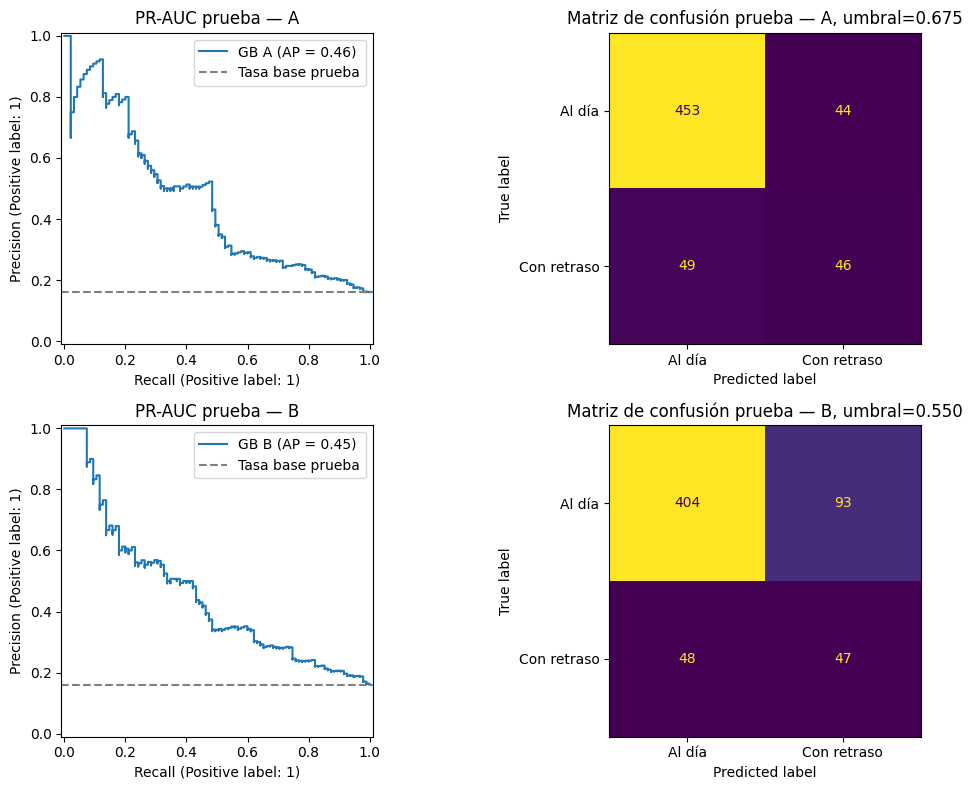

In [14]:
fig,axes=plt.subplots(2,2,figsize=(11,8))
for i,g in enumerate(('A','B')):
    thr=seleccionados[g]['val']['umbral']; p=predicciones[g]
    PrecisionRecallDisplay.from_predictions(y_test,p,ax=axes[i,0],name=f'GB {g}')
    axes[i,0].axhline(y_test.mean(),ls='--',color='gray',label='Tasa base prueba')
    axes[i,0].legend(); axes[i,0].set_title(f'PR-AUC prueba — {g}')
    ConfusionMatrixDisplay.from_predictions(y_test,p>=thr,ax=axes[i,1],
        display_labels=['Al día','Con retraso'],colorbar=False)
    axes[i,1].set_title(f'Matriz de confusión prueba — {g}, umbral={thr:.3f}')
plt.tight_layout();plt.savefig(OUT/'evaluacion_gradient_boosting_prueba.png',dpi=150);plt.show()


## 8. Priorización operativa en prueba
Para el analista, ordenar créditos por probabilidad y revisar el 10 %, 20 % o 30 % de mayor riesgo. Se reportan créditos revisados, retrasos encontrados, precisión top, recall top y créditos revisados por retraso detectado. Esta evaluación usa exclusivamente el conjunto de prueba.

In [15]:
def priorizacion(y,p):
    y=np.asarray(y,dtype=int); orden=np.argsort(-np.asarray(p),kind='stable'); yo=y[orden]
    filas=[]
    for frac in (.10,.20,.30):
        n=max(1,int(np.ceil(len(y)*frac))); encontrados=int(yo[:n].sum())
        filas.append({'porcentaje_revisado':int(frac*100),'creditos_revisados':n,
            'retrasos_encontrados':encontrados,'precision_top':encontrados/n,
            'recall_top':encontrados/int(y.sum()),
            'creditos_por_retraso':n/encontrados if encontrados else np.nan})
    return pd.DataFrame(filas)
tablas_prioridad=[]
for grupo in ('A','B'):
    t=priorizacion(y_test,predicciones[grupo]);t.insert(0,'grupo',grupo)
    tablas_prioridad.append(t)
prioridad=pd.concat(tablas_prioridad,ignore_index=True)
display(prioridad.round(3))
prioridad.to_csv(OUT/'priorizacion_creditos_prueba.csv',index=False)


,grupo,porcentaje_revisado,creditos_revisados,retrasos_encontrados,precision_top,recall_top,creditos_por_retraso
0,A,10,60,30,0.500,0.316,2.000
1,A,20,119,47,0.395,0.495,2.532
2,A,30,178,52,0.292,0.547,3.423
3,B,10,60,31,0.517,0.326,1.935
4,B,20,119,45,0.378,0.474,2.644
5,B,30,178,59,0.331,0.621,3.017


## 9. Interpretabilidad en validación
La importancia por permutación se calcula solo en validación para no reutilizar prueba en decisiones del modelo.

In [16]:
for grupo,item in seleccionados.items():
    pi=permutation_importance(item['pipe'],val[item['cols']],y_val,
        scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=1)
    tab=pd.DataFrame({'variable':item['cols'],'caida_pr_auc_media':pi.importances_mean,
        'desviacion':pi.importances_std}).sort_values('caida_pr_auc_media',ascending=False)
    tab.to_csv(OUT/f'importancia_permutacion_{grupo}.csv',index=False)
    print('Importancia por permutación',grupo);display(tab.round(4))


Importancia por permutación A


,variable,caida_pr_auc_media,desviacion
3,P2099S2,0.2228,0.0147
4,P2104,0.0291,0.0239
6,P2107S1,0.0290,0.0344
5,P2105S1,0.0208,0.0174
2,P2106,0.0115,0.0124
0,P2097,-0.0090,0.0045
1,P2098,-0.0111,0.0175


Importancia por permutación B


,variable,caida_pr_auc_media,desviacion
3,P2099S2,0.2060,0.0165
13,n_personas_trabajo_semana,0.0231,0.0027
5,P2105S1,0.0164,0.0164
2,P2106,0.0149,0.0153
6,P2107S1,0.0114,0.0246
10,prop_que_ahorran_sobre_con_ingresos,0.0091,0.0164
12,n_personas_laboral,0.0091,0.0045
7,n_personas_ahorro,0.0075,0.0069
4,P2104,0.0073,0.0179
8,n_personas_con_ingresos,0.0063,0.0044


## 10. Artefactos y MLflow centralizado
Se guardan los modelos A/B, el modelo ganador del algoritmo, las tablas y metadatos con hash del CSV. La selección se hace por PR-AUC de **validación** (desempate F1); no se usa prueba para elegir. El registro remoto solo se realiza si se configuró `MLFLOW_TRACKING_URI` al mismo servidor EC2 del equipo.

In [17]:
ganador=max(('A','B'),key=lambda g:(seleccionados[g]['val']['pr_auc'],seleccionados[g]['val']['f1']))
for grupo,item in seleccionados.items():
    joblib.dump(item['pipe'],OUT/f'pipeline_gradient_boosting_{grupo}.joblib')
joblib.dump(seleccionados[ganador]['pipe'],OUT/'gradient_boosting_pipeline_final.joblib')
metadata={'algoritmo':'HistGradientBoostingClassifier','modelo_seleccionado':ganador,
 'semilla':SEED,'segunda_semilla':SEED+1,'sha256_csv':HASH_DATOS,
 'fuente_csv':RUTA.name,'criterio_seleccion':'max PR-AUC validacion, desempate F1 validacion',
 'malla_umbrales':'0.10 a 0.90, paso 0.025; max F1 validacion',
 'conjuntos':{g:{'variables':seleccionados[g]['cols'],'configuracion':seleccionados[g]['cfg'],
 'umbral':seleccionados[g]['val']['umbral'],
 'metricas_prueba':{k.replace('test_',''):float(v) for k,v in res.set_index('grupo').loc[g].items()
                    if k.startswith('test_')}} for g in ('A','B')}}
(OUT/'metadata_modelo_final.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
for grupo,item in seleccionados.items():
    fila=res.set_index('grupo').loc[grupo]
    registrar(f'GB_FINAL_{grupo}',{'grupo':grupo,'configuracion':item['configuracion'],
        'umbral':item['val']['umbral'],**item['cfg']},
        {k:float(v) for k,v in fila.items() if k.startswith(('val_','test_'))},
        {'fase':'modelo_final' if grupo==ganador else 'comparacion_AB'},
        [OUT/'comparacion_AB_prueba.csv',OUT/'experimentos_validacion_gradient_boosting.csv',
         OUT/'priorizacion_creditos_prueba.csv',OUT/'particiones_comunes_grupo19.csv',
         OUT/f'pipeline_gradient_boosting_{grupo}.joblib',OUT/'metadata_modelo_final.json'])
print('Ganador de Gradient Boosting por validación:',ganador)
print('Resultados:',OUT.resolve())


Ganador de Gradient Boosting por validación: A
Resultados: /content/resultados_gradient_boosting_E3


## 11. Conclusiones y límites
- Comparar los tres algoritmos **solo sobre el mismo CSV y particiones**; verificar SHA256 y archivo `particiones_comunes_grupo19.csv`.
- La selección global entre algoritmos corresponde al equipo y se hará con PR-AUC en prueba como reporte final, **sin volver a ajustar parámetros**.
- Comparar A y B y aplicar el criterio del proyecto: Δrecall ≥ +0,05 y Δprecisión ≥ −0,03.
- Interpretar PR-AUC frente a la prevalencia y la tabla de priorización top 10/20/30 %.
- Los datos ELCO 2022 son observacionales: el modelo no constituye un sistema validado de aprobación de crédito.